# Crypto Intelligence: Ranking Large-Cap Cryptocurrencies

Ranks the largest cryptocurrencies on 90-day momentum, risk-adjusted return, trend, drawdown and liquidity, using the functions in `crypto_analysis.py`.

**Data mode:** set `LIVE = True` to pull the current top coins from CoinGecko and daily prices from Yahoo Finance. The outputs saved in this notebook come from `LIVE = False`, which uses **synthetic sample coins** (SAMPLE-01, SAMPLE-02, …) so the notebook runs anywhere without network access. The sample results are not market data.

In [1]:
LIVE = False

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import crypto_analysis as ca

pd.set_option('display.float_format', '{:,.3f}'.format)
sns.set_style('whitegrid')

if LIVE:
    universe = ca.fetch_universe(50)          # stablecoins and wrapped tokens removed
    prices = ca.fetch_prices(universe['symbol'], start='2024-01-01')
    universe = universe[universe['symbol'].isin(prices.columns)]
else:
    universe, prices = ca.sample_data()

print(f"{prices.shape[1]} coins, {len(prices)} days of prices ending {prices.index[-1]:%Y-%m-%d}")

20 coins, 540 days of prices ending 2025-09-30


## 1. Metrics

Over the last 90 days, for each coin:
- **return_90d**: price change
- **volatility_90d**: annualized standard deviation of daily returns (crypto trades 365 days a year)
- **sharpe_90d**: annualized return divided by volatility (no risk-free rate, so it's a simple risk-adjusted return)
- **max_drawdown_90d**: worst peak-to-trough fall
- **sma50_vs_sma200**: how far the 50-day average sits above the 200-day (trend)
- **rsi_14**: 14-day Relative Strength Index (above 70 often read as overbought, below 30 as oversold)
- **volume_to_mcap**: daily trading volume as a share of market cap (liquidity)

In [2]:
m = ca.metrics(prices, universe)
m[['return_90d', 'volatility_90d', 'sharpe_90d', 'max_drawdown_90d', 'sma50_vs_sma200', 'rsi_14', 'volume_to_mcap']].describe().loc[['mean', 'min', '50%', 'max']]

,return_90d,volatility_90d,sharpe_90d,max_drawdown_90d,sma50_vs_sma200,rsi_14,volume_to_mcap
mean,0.283,0.875,1.355,-0.297,0.106,56.339,0.075
min,-0.215,0.549,-0.615,-0.491,-0.155,32.131,0.013
50%,0.148,0.821,1.070,-0.272,0.104,56.892,0.074
max,1.507,1.246,5.022,-0.147,0.404,81.330,0.137


## 2. Ranking

Each metric is turned into a percentile rank (0 to 1) across coins before weighting. Without that step, a metric measured on a 0–100 scale such as RSI would swamp ratios measured around 0–1.

| Component | Weight |
|---|---|
| Sharpe (90d) | 30% |
| Momentum (90d return) | 25% |
| Trend (SMA50 vs SMA200) | 15% |
| Drawdown (smaller is better) | 15% |
| Liquidity (volume / market cap) | 15% |

RSI is not part of the score. It is shown as a flag, because a high score combined with "Overbought" is a reason to wait for a better entry rather than a reason to rank higher or lower.

In [3]:
ranked = ca.rank(m)
ranked[['name', 'return_90d', 'volatility_90d', 'sharpe_90d', 'max_drawdown_90d', 'rsi_14', 'score', 'rsi_flag']].head(10)

,name,return_90d,volatility_90d,sharpe_90d,max_drawdown_90d,rsi_14,score,rsi_flag
SAMPLE-06,Sample coin 6,1.507,0.919,4.576,-0.213,81.330,88.000,Overbought
SAMPLE-04,Sample coin 4,1.410,0.782,5.022,-0.303,80.008,85.200,Overbought
SAMPLE-20,Sample coin 20,1.066,0.800,4.127,-0.168,69.741,83.200,
SAMPLE-09,Sample coin 9,0.327,0.637,2.141,-0.202,62.958,78.200,
SAMPLE-11,Sample coin 11,0.470,0.843,2.293,-0.206,57.797,72.200,
SAMPLE-14,Sample coin 14,0.323,1.071,1.597,-0.295,51.696,64.200,
SAMPLE-08,Sample coin 8,0.115,0.731,0.969,-0.147,44.955,63.500,
SAMPLE-03,Sample coin 3,0.441,1.046,1.954,-0.238,63.649,62.000,
SAMPLE-16,Sample coin 16,0.181,1.000,1.171,-0.403,40.317,56.500,
SAMPLE-01,Sample coin 1,0.387,1.246,1.690,-0.286,70.277,51.000,Overbought


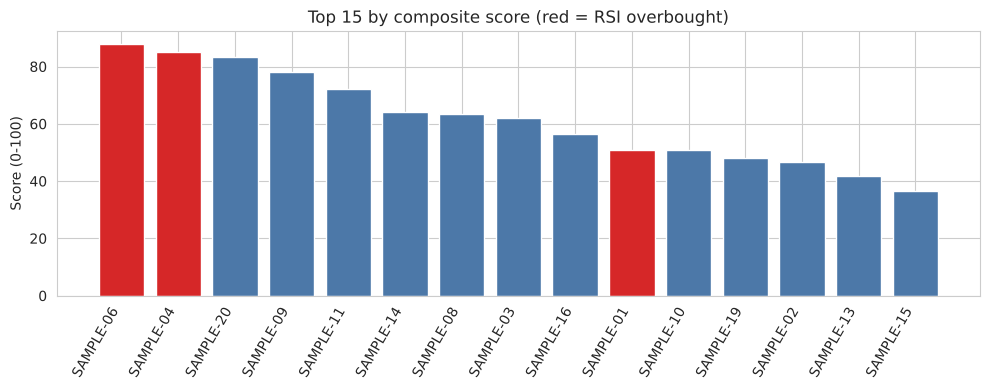

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
top = ranked.head(15)
ax.bar(top.index, top['score'], color=['#d62728' if f == 'Overbought' else '#4C78A8' for f in top['rsi_flag']])
ax.set_ylabel('Score (0-100)')
ax.set_title('Top 15 by composite score (red = RSI overbought)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()

## 3. Risk and return

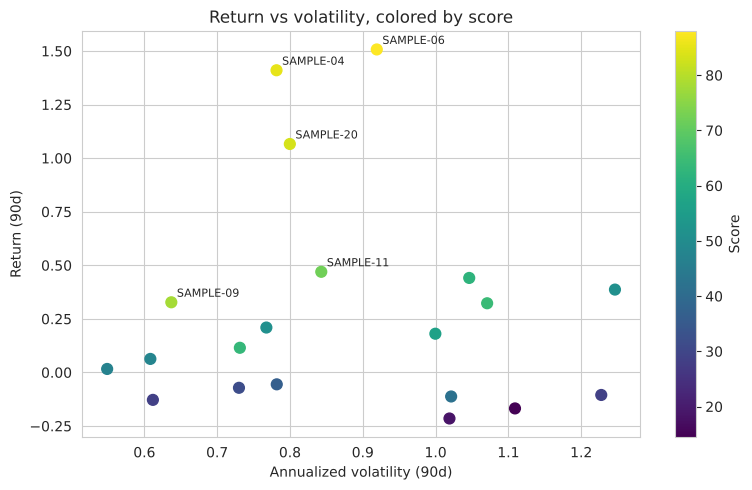

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(ranked['volatility_90d'], ranked['return_90d'], c=ranked['score'], cmap='viridis', s=60)
for sym, r in ranked.head(5).iterrows():
    ax.annotate(sym, (r['volatility_90d'], r['return_90d']), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Annualized volatility (90d)')
ax.set_ylabel('Return (90d)')
ax.set_title('Return vs volatility, colored by score')
plt.colorbar(sc, label='Score')
plt.tight_layout()

## 4. Correlation
Most coins move with the market leader, which limits how much diversification holding several of them provides.

Median 90-day correlation to SAMPLE-01: 0.42


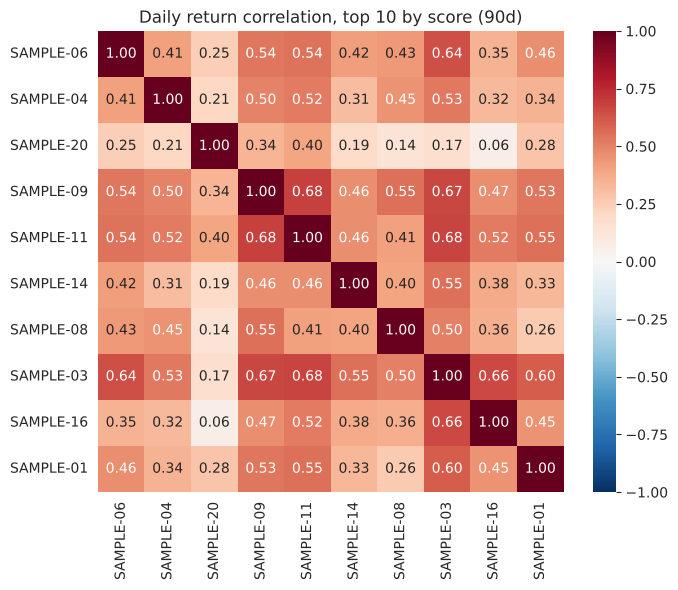

In [6]:
anchor = 'BTC' if LIVE else ranked['market_cap'].idxmax()
corr = ca.correlation_to(prices, anchor)
print(f"Median 90-day correlation to {anchor}: {corr.median():.2f}")
top10 = ranked.head(10).index
plt.figure(figsize=(7, 6))
sns.heatmap(prices[top10].iloc[-90:].pct_change().corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Daily return correlation, top 10 by score (90d)')
plt.tight_layout()

## Takeaways and limits

- The score rewards coins that have risen with less volatility and smaller drawdowns, in liquid markets. It describes recent behavior and is not a forecast or investment advice.
- 90 days is short for crypto. Re-running with a longer lookback (the `lookback` argument to `ca.metrics`) shows how stable the ranking is.
- High correlations mean a basket of top-ranked coins behaves much like a single position in the market leader.